In [66]:
!git clone https://github.com/salesforce/WikiSQL
!cd WikiSQL && tar xvjf data.tar.bz2
!cd WikiSQL && zip -r wikisql_data.zip data/
import os
print(os.listdir("WikiSQL/data"))

fatal: destination path 'WikiSQL' already exists and is not an empty directory.
data/
data/train.jsonl
data/test.tables.jsonl
data/test.db
data/dev.tables.jsonl
data/dev.db
data/test.jsonl
data/train.tables.jsonl
data/train.db
data/dev.jsonl
updating: data/ (stored 0%)
updating: data/test.db (deflated 85%)
updating: data/dev.tables.jsonl (deflated 73%)
updating: data/test.tables.jsonl (deflated 73%)
updating: data/train.db (deflated 86%)
updating: data/train.tables.jsonl (deflated 75%)
updating: data/test.jsonl (deflated 82%)
updating: data/dev.jsonl (deflated 82%)
updating: data/dev.db (deflated 86%)
updating: data/train.jsonl (deflated 82%)
['test.db', 'dev.tables.jsonl', 'test.tables.jsonl', 'train.db', 'train.tables.jsonl', 'test.jsonl', 'dev.jsonl', 'dev.db', 'train.jsonl']


# Section 1 — Starter code

In [67]:
import json
from pathlib import Path

DATA_DIR = Path("WikiSQL/data")
AGG_OPS = ["", "MAX", "MIN", "COUNT", "SUM", "AVG"]
COND_OPS = ["=", ">", "<"]
MAX_COLS = 64

def load_split(split):
    tables = {}
    with open(DATA_DIR / f"{split}.tables.jsonl", encoding="utf-8") as f:
        for line in f:
            t = json.loads(line)
            tables[t["id"]] = t
    with open(DATA_DIR / f"{split}.jsonl", encoding="utf-8") as f:
        examples = [json.loads(line) for line in f]
    return examples, tables

def encode_source(question, header):
    cols = " ".join(f"<c{i}> {name}" for i, name in enumerate(header))
    return f"{question.strip()} <sep> {cols}".lower()

def encode_target(sql):
    out = ["select"]
    if sql["agg"]:
        out.append(AGG_OPS[sql["agg"]].lower())
    out.append(f"<c{sql['sel']}>")
    for i, (col, op, val) in enumerate(sql["conds"]):
        out += ["where" if i == 0 else "and", f"<c{col}>", COND_OPS[op], str(val)]
    return " ".join(out).lower()

def build_pairs(split):
    examples, tables = load_split(split)
    pairs = []
    for ex in examples:
        header = tables[ex["table_id"]]["header"]
        pairs.append({
            "table_id": ex["table_id"],
            "src": encode_source(ex["question"], header),
            "tgt": encode_target(ex["sql"]),
        })
    return pairs

for split in ["train", "dev", "test"]:
    pairs = build_pairs(split)
    with open(f"{split}_pairs.jsonl", "w", encoding="utf-8") as f:
        for p in pairs:
            f.write(json.dumps(p, ensure_ascii=False) + "\n")
    print(f"{split}: {len(pairs)} pairs")

print(pairs[0]["src"])
print(pairs[0]["tgt"])

train: 56355 pairs
dev: 8421 pairs
test: 15878 pairs
what is terrence ross' nationality <sep> <c0> player <c1> no. <c2> nationality <c3> position <c4> years in toronto <c5> school/club team
select <c2> where <c0> = terrence ross


# tokenizer

In [68]:
import json
import sentencepiece as spm

PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
SPECIAL = ["<sep>"] + [f"<c{i}>" for i in range(MAX_COLS)]

def read_pairs(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]

def train_tokenizer(train_path="train_pairs.jsonl", vocab_size=8000):
    pairs = read_pairs(train_path)
    with open("spm_corpus.txt", "w", encoding="utf-8") as f:
        for p in pairs:
            f.write(p["src"] + "\n")
            f.write(p["tgt"] + "\n")
    spm.SentencePieceTrainer.train(
        input="spm_corpus.txt", model_prefix="sql_sp",
        vocab_size=vocab_size, model_type="bpe",
        character_coverage=1.0,
        user_defined_symbols=SPECIAL,
        pad_id=PAD_ID, unk_id=UNK_ID, bos_id=BOS_ID, eos_id=EOS_ID,
    )
    return spm.SentencePieceProcessor(model_file="sql_sp.model")

sp = train_tokenizer()
p = read_pairs("dev_pairs.jsonl")[0]
print(sp.encode(p["src"], out_type=str))
print(sp.encode(p["tgt"], out_type=str))
print(sp.decode(sp.encode(p["tgt"])) == p["tgt"])

I0000 00:00:1791157614.894290      49 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: spm_corpus.txt
  input_format: 
  model_prefix: sql_sp
  model_type: BPE
  vocab_size: 8000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  user_defined_symbols: <sep>
  user_defined_symbols: <c0>
  user_defined_symbols: <c1>
  user_defined_symbols: <c2>
  user_defined_symbols: <c3>
  user_defined_symbols: <c4>
  user_defined_symbols: <c5>
  user_defined_symbols: <c6>
  user_defined_symbols: <c7>
  user_defined_symbols: <c8>
  user_defined_symbols: <c9>
  user_defined_sym

['▁what', '▁position', '▁does', '▁the', '▁player', '▁who', '▁played', '▁for', '▁but', 'ler', '▁cc', '▁(', 'ks', ')', '▁play', '?', '▁', '<sep>', '▁', '<c0>', '▁player', '▁', '<c1>', '▁no', '.', '▁', '<c2>', '▁nationality', '▁', '<c3>', '▁position', '▁', '<c4>', '▁years', '▁in', '▁toronto', '▁', '<c5>', '▁school', '/', 'club', '▁team']
['▁select', '▁', '<c3>', '▁where', '▁', '<c5>', '▁=', '▁but', 'ler', '▁cc', '▁(', 'ks', ')']
True


# dataset

In [69]:
import torch
from torch.utils.data import Dataset, DataLoader

class SQLDataset(Dataset):
    def __init__(self, path, sp, train=True, max_src=160, max_tgt=64):
        self.items, skipped = [], 0
        for p in read_pairs(path):
            src = sp.encode(p["src"]) + [EOS_ID]
            tgt = [BOS_ID] + sp.encode(p["tgt"]) + [EOS_ID]
            if train and (len(src) > max_src or len(tgt) > max_tgt):
                skipped += 1
                continue
            self.items.append((src, tgt))
        print(f"{path}: kept {len(self.items)}, skipped {skipped}")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        return self.items[i]

def collate(batch):
    srcs, tgts = zip(*batch)
    S, T = max(map(len, srcs)), max(map(len, tgts))
    src = torch.full((len(batch), S), PAD_ID, dtype=torch.long)
    tgt = torch.full((len(batch), T), PAD_ID, dtype=torch.long)
    for i, (s, t) in enumerate(zip(srcs, tgts)):
        src[i, :len(s)] = torch.tensor(s)
        tgt[i, :len(t)] = torch.tensor(t)
    return src, tgt

def make_loader(path, sp, train, batch_size=64):
    return DataLoader(SQLDataset(path, sp, train=train),
                       batch_size=batch_size, shuffle=train,
                       collate_fn=collate)

# embeddings

In [70]:
import math
import torch
import torch.nn as nn

class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, pad_id=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.scale = math.sqrt(d_model)

    def forward(self, ids):
        return self.emb(ids) * self.scale

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])

class InputLayer(nn.Module):
    def __init__(self, token_emb, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.tok = token_emb
        self.pos = PositionalEncoding(d_model, max_len, dropout)

    def forward(self, ids):
        return self.pos(self.tok(ids))

In [71]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dl = make_loader("train_pairs.jsonl", sp, train=True)
dev_dl = make_loader("dev_pairs.jsonl", sp, train=False)

src, tgt = next(iter(train_dl))
print("src", tuple(src.shape), "tgt", tuple(tgt.shape))

d_model = 256
shared = TokenEmbedding(sp.get_piece_size(), d_model, PAD_ID)
enc_in = InputLayer(shared, d_model)
dec_in = InputLayer(shared, d_model)

x = enc_in(src)
y = dec_in(tgt[:, :-1])
print("encoder input", tuple(x.shape), "decoder input", tuple(y.shape))

train_pairs.jsonl: kept 56336, skipped 19
dev_pairs.jsonl: kept 8421, skipped 0
src (64, 83) tgt (64, 33)
encoder input (64, 83, 256) decoder input (64, 32, 256)


# Report pairs per split, mean/max source and target length in tokens

In [72]:
import numpy as np

def report_stats(path, sp):
    pairs = read_pairs(path)
    src_lens = [len(sp.encode(p["src"])) for p in pairs]
    tgt_lens = [len(sp.encode(p["tgt"])) for p in pairs]
    print(f"{path}: {len(pairs)} pairs")
    print(f"  source length -- mean: {np.mean(src_lens):.1f}, max: {max(src_lens)}")
    print(f"  target length -- mean: {np.mean(tgt_lens):.1f}, max: {max(tgt_lens)}")

for split in ["train", "dev", "test"]:
    report_stats(f"{split}_pairs.jsonl", sp)

train_pairs.jsonl: 56355 pairs
  source length -- mean: 41.5, max: 221
  target length -- mean: 12.8, max: 63
dev_pairs.jsonl: 8421 pairs
  source length -- mean: 41.5, max: 166
  target length -- mean: 12.8, max: 42
test_pairs.jsonl: 15878 pairs
  source length -- mean: 41.7, max: 259
  target length -- mean: 12.9, max: 44


# Positional-encoding heatmap

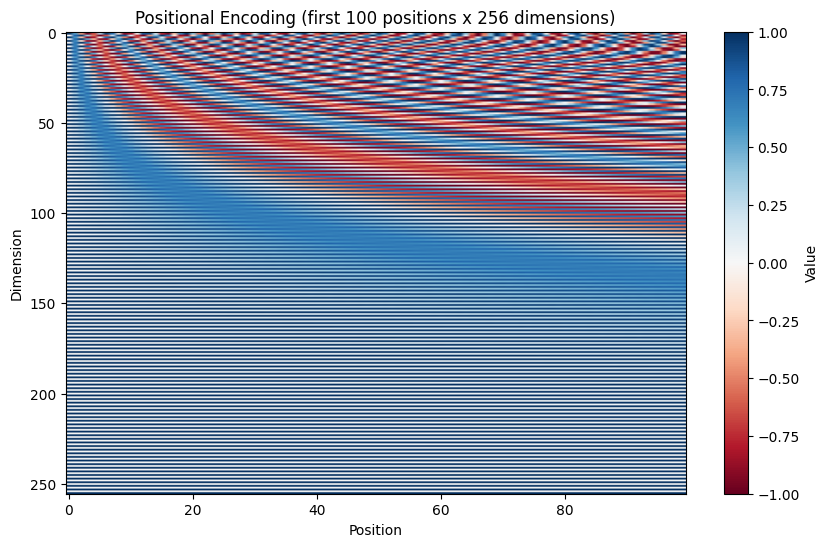

In [73]:
import matplotlib.pyplot as plt

pe_module = PositionalEncoding(d_model=256, max_len=512, dropout=0.0)
pe_matrix = pe_module.pe[0, :100, :].numpy()  # first 100 positions x 256 dims

plt.figure(figsize=(10, 6))
plt.imshow(pe_matrix.T, aspect="auto", cmap="RdBu")
plt.xlabel("Position")
plt.ylabel("Dimension")
plt.title("Positional Encoding (first 100 positions x 256 dimensions)")
plt.colorbar(label="Value")
plt.savefig("/kaggle/working/positional_encoding1.png", dpi=150, bbox_inches="tight")
plt.show()

In [74]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class ScaledDotProductAttention(nn.Module):
    """Attention(Q, K, V) = softmax(QK^T / sqrt(d_k)) V"""
    def forward(self, Q, K, V, mask=None):
        # Q: (B, h, Lq, d_k)
        # K: (B, h, Lk, d_k)
        # V: (B, h, Lk, d_v)
        # mask: (B, 1, Lq, Lk) or (B, 1, 1, Lk) -- broadcastable, 1 = keep, 0 = hide

        d_k = Q.size(-1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)  # (B, h, Lq, Lk)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, float("-inf"))

        attn_weights = F.softmax(scores, dim=-1)  # (B, h, Lq, Lk)
        output = torch.matmul(attn_weights, V)      # (B, h, Lq, d_v)
        return output, attn_weights

In [75]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=256, num_heads=4, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads  # 256 / 4 = 64, matches d_k = d_v = 64 in the manual

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attention = ScaledDotProductAttention()
        self.dropout = nn.Dropout(dropout)

    def split_heads(self, x):
        # x: (B, L, d_model) -> (B, h, L, d_k)
        B, L, _ = x.shape
        x = x.view(B, L, self.num_heads, self.d_k)
        return x.transpose(1, 2)  # (B, h, L, d_k)

    def combine_heads(self, x):
        # x: (B, h, L, d_k) -> (B, L, d_model)
        B, h, L, d_k = x.shape
        x = x.transpose(1, 2).contiguous()  # (B, L, h, d_k)
        return x.view(B, L, h * d_k)

    def forward(self, query, key, value, mask=None):
        Q = self.split_heads(self.W_q(query))  # (B, h, Lq, d_k)
        K = self.split_heads(self.W_k(key))     # (B, h, Lk, d_k)
        V = self.split_heads(self.W_v(value))   # (B, h, Lk, d_k)

        attn_output, attn_weights = self.attention(Q, K, V, mask=mask)
        attn_output = self.dropout(attn_output)

        combined = self.combine_heads(attn_output)  # (B, Lq, d_model)
        output = self.W_o(combined)
        return output, attn_weights

In [76]:
def make_padding_mask(seq, pad_id=0):
    # seq: (B, L) token ids
    # returns: (B, 1, 1, L) -- 1 = keep (real token), 0 = hide (pad)
    mask = (seq != pad_id).unsqueeze(1).unsqueeze(2)  # (B, 1, 1, L)
    return mask.long()

In [77]:
def make_causal_mask(L, device):
    # returns: (1, 1, L, L) -- lower triangular, 1 = keep, 0 = hide
    mask = torch.tril(torch.ones(L, L, device=device)).unsqueeze(0).unsqueeze(0)
    return mask.long()

In [78]:
def make_decoder_self_attn_mask(tgt, pad_id=0):
    # tgt: (B, L)
    B, L = tgt.shape
    pad_mask = make_padding_mask(tgt, pad_id)              # (B, 1, 1, L)
    causal_mask = make_causal_mask(L, tgt.device)            # (1, 1, L, L)
    combined = pad_mask & causal_mask                         # broadcasts to (B, 1, L, L)
    return combined.long()

In [79]:
# padding mask test
seq = torch.tensor([[5, 6, 7, 0, 0]])  # 3 real tokens, 2 pads
pm = make_padding_mask(seq, pad_id=0)
print(pm.shape)        # (1, 1, 1, 5)
print(pm.squeeze())    # tensor([1, 1, 1, 0, 0])

# causal mask test
cm = make_causal_mask(5, device="cpu")
print(cm.squeeze())
# expect lower-triangular 5x5: row 0 can see col 0 only, row 4 can see all 5

torch.Size([1, 1, 1, 5])
tensor([1, 1, 1, 0, 0])
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]])


In [80]:
class PositionwiseFeedForward(nn.Module):
    """FFN(x) = max(0, xW1 + b1)W2 + b2"""
    def __init__(self, d_model=256, d_ff=1024, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, L, d_model)
        return self.linear2(self.dropout(F.relu(self.linear1(x))))
        

class SublayerConnection(nn.Module):
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer_output):
        return x + self.dropout(sublayer_output)

In [81]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model=256, num_heads=4, d_ff=1024, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ffn = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.sublayer1 = SublayerConnection(d_model, dropout)
        self.sublayer2 = SublayerConnection(d_model, dropout)

    
    def forward(self, x, src_mask):
        norm_x = self.sublayer1.norm(x)
        attn_out, attn_weights = self.self_attn(
            norm_x, norm_x, norm_x, mask=src_mask
        )
        x = self.sublayer1(x, attn_out)

        norm_x = self.sublayer2.norm(x)
        ffn_out = self.ffn(norm_x)
        x = self.sublayer2(x, ffn_out)

        return x, attn_weights

In [82]:
class Encoder(nn.Module):
    def __init__(self, d_model=256, num_heads=4, d_ff=1024, num_layers=3, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)
        ])

    def forward(self, x, src_mask):
        attn_weights_all = []
        for layer in self.layers:
            x, attn_weights = layer(x, src_mask)
            attn_weights_all.append(attn_weights)
        return x, attn_weights_all

In [83]:

class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ffn = PositionwiseFeedForward(d_model, d_ff, dropout)

        # Pre-LayerNorm sublayers
        self.sublayer1 = SublayerConnection(d_model, dropout)
        self.sublayer2 = SublayerConnection(d_model, dropout)
        self.sublayer3 = SublayerConnection(d_model, dropout)

    def forward(self, x, encoder_output, self_mask, cross_mask):

        # Masked self-attention
        norm_x = self.sublayer1.norm(x)

        self_attn_out, self_attn_weights = self.self_attn(
            norm_x, norm_x, norm_x, mask=self_mask
        )

        x = self.sublayer1(x, self_attn_out)

        # Cross-attention
        norm_x = self.sublayer2.norm(x)

        cross_attn_out, cross_attn_weights = self.cross_attn(
            norm_x, encoder_output, encoder_output, mask=cross_mask
        )

        x = self.sublayer2(x, cross_attn_out)

        # Feed-forward network
        norm_x = self.sublayer3.norm(x)

        ffn_out = self.ffn(norm_x)

        x = self.sublayer3(x, ffn_out)

        return x, self_attn_weights, cross_attn_weights

In [84]:
class Decoder(nn.Module):
    def __init__(self, d_model=256, num_heads=4, d_ff=1024, num_layers=3, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)
        ])

    def forward(self, x, encoder_output, self_mask, cross_mask):
        self_attns, cross_attns = [], []
        for layer in self.layers:
            x, self_attn_w, cross_attn_w = layer(x, encoder_output, self_mask, cross_mask)
            self_attns.append(self_attn_w)
            cross_attns.append(cross_attn_w)
        return x, self_attns, cross_attns

In [85]:
class Transformer(nn.Module):
    def __init__(self, vocab_size, d_model=256, num_heads=4, d_ff=1024,
                 num_enc_layers=3, num_dec_layers=3, dropout=0.1,
                 pad_id=0, max_len=512):
        super().__init__()
        self.pad_id = pad_id

        # Shared embedding -- ONE TokenEmbedding instance used by both input layers
        self.shared_embedding = TokenEmbedding(vocab_size, d_model, pad_id)
        self.enc_input = InputLayer(self.shared_embedding, d_model, max_len, dropout)
        self.dec_input = InputLayer(self.shared_embedding, d_model, max_len, dropout)

        self.encoder = Encoder(d_model, num_heads, d_ff, num_enc_layers, dropout)
        self.decoder = Decoder(d_model, num_heads, d_ff, num_dec_layers, dropout)

        # Output projection -- weight TIED to the embedding matrix (Section 3.4 of the paper)
        self.output_proj = nn.Linear(d_model, vocab_size, bias=False)
        self.output_proj.weight = self.shared_embedding.emb.weight  # literally the same tensor

    def encode(self, src, src_mask):
        x = self.enc_input(src)
        return self.encoder(x, src_mask)  # (enc_out, enc_self_attns)

    def decode(self, tgt, encoder_output, self_mask, cross_mask):
        y = self.dec_input(tgt)
        return self.decoder(y, encoder_output, self_mask, cross_mask)  # (dec_out, self_attns, cross_attns)

    def forward(self, src, tgt):
        src_mask = make_padding_mask(src, self.pad_id)
        tgt_self_mask = make_decoder_self_attn_mask(tgt, self.pad_id)
        cross_mask = make_padding_mask(src, self.pad_id)  # hides encoder's padded positions

        enc_out, enc_attns = self.encode(src, src_mask)
        dec_out, dec_self_attns, dec_cross_attns = self.decode(tgt, enc_out, tgt_self_mask, cross_mask)

        logits = self.output_proj(dec_out)  # (B, L, vocab_size)
        return logits, dec_cross_attns

In [86]:
model = Transformer(vocab_size=sp.get_piece_size(), d_model=256, num_heads=4,
                     d_ff=1024, num_enc_layers=3, num_dec_layers=3, dropout=0.1)

src, tgt = next(iter(train_dl))
logits, cross_attns = model(src, tgt[:, :-1])  # decoder input = tgt minus last token (teacher forcing setup)

print(logits.shape)  # expect (B, tgt_len-1, vocab_size)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

torch.Size([64, 29, 8000])
Trainable parameters: 7,577,600


In [87]:
model.eval()
with torch.no_grad():
    src_test = src[:1]
    tgt_test = tgt[:1, :-1].clone()

    logits1, _ = model(src_test, tgt_test)

    tgt_test_modified = tgt_test.clone()
    tgt_test_modified[0, -1] = (tgt_test_modified[0, -1] + 1) % sp.get_piece_size()  # change last token
    logits2, _ = model(src_test, tgt_test_modified)

    # all positions EXCEPT the last should be identical
    print(torch.allclose(logits1[:, :-1], logits2[:, :-1], atol=1e-5))  # should print True

True


In [88]:
with torch.no_grad():
    src_short = src[:1, :5]  # take a short real prefix
    src_padded = F.pad(src_short, (0, 5), value=PAD_ID)  # add 5 extra pad tokens

    logits_short, _ = model.encode(src_short, make_padding_mask(src_short, PAD_ID))
    logits_padded, _ = model.encode(src_padded, make_padding_mask(src_padded, PAD_ID))

    print(torch.allclose(logits_short, logits_padded[:, :5], atol=1e-5))  # should print True

True


In [89]:
import math

class TransformerLRSchedule:
    def __init__(self, optimizer, d_model=256, warmup_steps=4000):
        self.optimizer = optimizer
        self.d_model = d_model
        self.warmup_steps = warmup_steps
        self.step_num = 0

    def step(self):
        self.step_num += 1
        lr = self._compute_lr()
        for param_group in self.optimizer.param_groups:
            param_group["lr"] = lr
        return lr

    def _compute_lr(self):
        step = self.step_num
        return (self.d_model ** -0.5) * min(step ** -0.5, step * (self.warmup_steps ** -1.5))

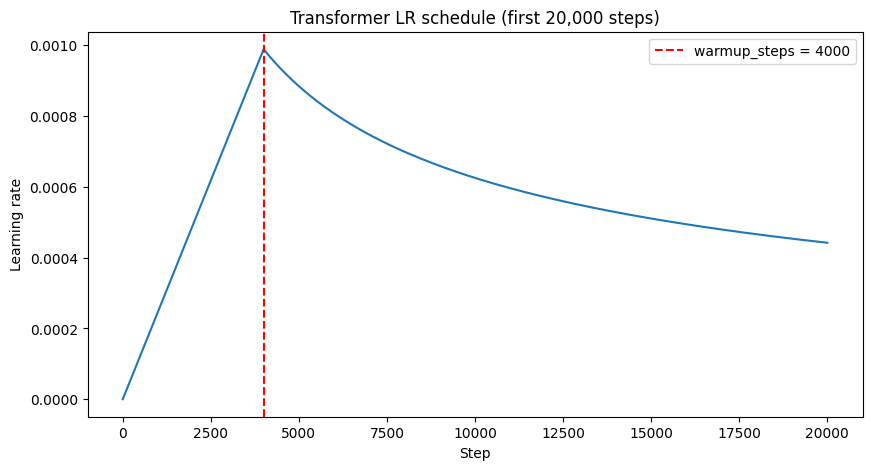

In [90]:
import matplotlib.pyplot as plt

dummy_optimizer = torch.optim.Adam([torch.nn.Parameter(torch.zeros(1))])
schedule = TransformerLRSchedule(dummy_optimizer, d_model=256, warmup_steps=4000)

lrs = [schedule.step() for _ in range(20000)]

plt.figure(figsize=(10, 5))
plt.plot(lrs)
plt.axvline(4000, color="red", linestyle="--", label="warmup_steps = 4000")
plt.xlabel("Step")
plt.ylabel("Learning rate")
plt.title("Transformer LR schedule (first 20,000 steps)")
plt.legend()
plt.savefig("/kaggle/working/lr_schedule.png", dpi=150, bbox_inches="tight")
plt.show()

In [91]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID, label_smoothing=0.1)

In [92]:
optimizer = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)

In [93]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Transformer(vocab_size=sp.get_piece_size(), d_model=256, num_heads=4,
                     d_ff=1024, num_enc_layers=3, num_dec_layers=3, dropout=0.1).to(device)

# --- NEW: fix embedding scale ---
nn.init.normal_(model.shared_embedding.emb.weight, mean=0, std=256 ** -0.5)
with torch.no_grad():
    model.shared_embedding.emb.weight[PAD_ID].fill_(0)

# --- NEW: Xavier init on all Linear layers ---
def init_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
model.apply(init_weights)
# --- end new code ---

model.apply(init_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
scheduler = TransformerLRSchedule(optimizer, d_model=256, warmup_steps=4000)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID, label_smoothing=0.1)


def train_epoch(model, dataloader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0

    for src, tgt in dataloader:
        src, tgt = src.to(device), tgt.to(device)

        decoder_input = tgt[:, :-1]
        decoder_target = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)

        logits, _ = model(src, decoder_input)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            decoder_target.reshape(-1)
        )

        loss.backward()

        # Prevent unusually large gradient updates
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Set the learning rate BEFORE updating model parameters
        lr = scheduler.step()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

@torch.no_grad()
def evaluate_epoch(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    for src, tgt in dataloader:
        src, tgt = src.to(device), tgt.to(device)
        decoder_input = tgt[:, :-1]
        decoder_target = tgt[:, 1:]
        logits, _ = model(src, decoder_input)
        loss = criterion(logits.reshape(-1, logits.size(-1)), decoder_target.reshape(-1))
        total_loss += loss.item()
    return total_loss / len(dataloader)

In [95]:
import os, json, time

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("results", exist_ok=True)

N_EPOCHS = 25
best_dev_loss = float("inf")
history = {"train_loss": [], "dev_loss": [], "lr": []}

start_time = time.time()
for epoch in range(1, N_EPOCHS + 1):
    epoch_start = time.time()
    train_loss = train_epoch(model, train_dl, optimizer, scheduler, criterion, device)
    dev_loss = evaluate_epoch(model, dev_dl, criterion, device)
    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["dev_loss"].append(dev_loss)
    history["lr"].append(current_lr)

    print(f"Epoch {epoch}/{N_EPOCHS} | train_loss={train_loss:.4f} | dev_loss={dev_loss:.4f} | "
          f"lr={current_lr:.2e} | time={time.time()-epoch_start:.1f}s")

    if dev_loss < best_dev_loss:
        best_dev_loss = dev_loss
        torch.save(model.state_dict(), "checkpoints/best_model.pt")
        print(f"  -> new best checkpoint saved (dev_loss={dev_loss:.4f})")

    with open("results/history.json", "w") as f:
        json.dump(history, f)

print(f"Total training time: {(time.time()-start_time)/60:.1f} minutes")

Epoch 1/25 | train_loss=1.9922 | dev_loss=1.8846 | lr=9.32e-04 | time=65.5s
  -> new best checkpoint saved (dev_loss=1.8846)
Epoch 2/25 | train_loss=1.8772 | dev_loss=1.7770 | lr=9.16e-04 | time=65.1s
  -> new best checkpoint saved (dev_loss=1.7770)
Epoch 3/25 | train_loss=1.7606 | dev_loss=1.7088 | lr=8.40e-04 | time=65.2s
  -> new best checkpoint saved (dev_loss=1.7088)
Epoch 4/25 | train_loss=1.6811 | dev_loss=1.6557 | lr=7.80e-04 | time=65.3s
  -> new best checkpoint saved (dev_loss=1.6557)
Epoch 5/25 | train_loss=1.6268 | dev_loss=1.6151 | lr=7.32e-04 | time=65.1s
  -> new best checkpoint saved (dev_loss=1.6151)
Epoch 6/25 | train_loss=1.5839 | dev_loss=1.5969 | lr=6.91e-04 | time=65.1s
  -> new best checkpoint saved (dev_loss=1.5969)
Epoch 7/25 | train_loss=1.5498 | dev_loss=1.5691 | lr=6.57e-04 | time=65.3s
  -> new best checkpoint saved (dev_loss=1.5691)
Epoch 8/25 | train_loss=1.5189 | dev_loss=1.5468 | lr=6.27e-04 | time=65.4s
  -> new best checkpoint saved (dev_loss=1.5468)


In [96]:

def check_gradients(model):

    print("\nGradient Norms")

    checks = {
        "Encoder layer 0": model.encoder.layers[0].self_attn.W_q.weight,
        "Encoder layer 2": model.encoder.layers[2].self_attn.W_q.weight,
        "Decoder layer 0": model.decoder.layers[0].self_attn.W_q.weight,
        "Decoder layer 2": model.decoder.layers[2].self_attn.W_q.weight,
    }

    for name, param in checks.items():

        if param.grad is not None:
            print(f"{name}: {param.grad.norm().item():.10e}")
        else:
            print(f"{name}: No gradient")

check_gradients(model)


Gradient Norms
Encoder layer 0: 3.6374017596e-02
Encoder layer 2: 2.9128134251e-02
Decoder layer 0: 1.4272409491e-02
Decoder layer 2: 2.0555498078e-02


In [97]:
def inspect_all_gradients(model):
    print("\n========== GRADIENT ANALYSIS ==========")

    for name, param in model.named_parameters():
        if param.grad is not None:
            print(
                f"{name:65s} "
                f"{param.grad.norm().item():.10e}"
            )

inspect_all_gradients(model)


========== GRADIENT ANALYSIS ==========
shared_embedding.emb.weight                                       9.0226542950e-01
encoder.layers.0.self_attn.W_q.weight                             3.6374017596e-02
encoder.layers.0.self_attn.W_q.bias                               5.9220013209e-03
encoder.layers.0.self_attn.W_k.weight                             3.6816548556e-02
encoder.layers.0.self_attn.W_k.bias                               1.4099164058e-09
encoder.layers.0.self_attn.W_v.weight                             1.3720221817e-01
encoder.layers.0.self_attn.W_v.bias                               3.0670832843e-02
encoder.layers.0.self_attn.W_o.weight                             1.0728031397e-01
encoder.layers.0.self_attn.W_o.bias                               2.3967344314e-02
encoder.layers.0.ffn.linear1.weight                               8.7463296950e-02
encoder.layers.0.ffn.linear1.bias                                 1.0017125867e-02
encoder.layers.0.ffn.linear2.weight           

In [98]:
def collect_gradient_stats(model, dataloader, criterion, device, num_batches=10):

    model.train()

    tracked_params = {
        "Decoder L0 W_q": model.decoder.layers[0].self_attn.W_q.weight,
        "Decoder L1 W_q": model.decoder.layers[1].self_attn.W_q.weight,
        "Decoder L2 W_q": model.decoder.layers[2].self_attn.W_q.weight,

        "Decoder L0 W_k": model.decoder.layers[0].self_attn.W_k.weight,
        "Decoder L1 W_k": model.decoder.layers[1].self_attn.W_k.weight,
        "Decoder L2 W_k": model.decoder.layers[2].self_attn.W_k.weight,
    }

    gradient_stats = {name: [] for name in tracked_params}

    for i, (src, tgt) in enumerate(dataloader):

        if i >= num_batches:
            break

        src, tgt = src.to(device), tgt.to(device)

        decoder_input = tgt[:, :-1]
        decoder_target = tgt[:, 1:]

        model.zero_grad(set_to_none=True)

        logits, _ = model(src, decoder_input)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            decoder_target.reshape(-1)
        )

        loss.backward()

        for name, param in tracked_params.items():
            gradient_stats[name].append(param.grad.norm().item())

    print("\nAverage Gradient Norms")

    for name, values in gradient_stats.items():
        print(f"{name}: {sum(values) / len(values):.10e}")

collect_gradient_stats(model, train_dl, criterion, device, num_batches=10)


Average Gradient Norms
Decoder L0 W_q: 9.3555445317e-03
Decoder L1 W_q: 9.9583956879e-03
Decoder L2 W_q: 9.4216460828e-03
Decoder L0 W_k: 1.0331085417e-02
Decoder L1 W_k: 1.0012375144e-02
Decoder L2 W_k: 9.6422328614e-03


In [99]:
@torch.no_grad()
def decode_greedy(model, sp, src_text, device, max_len=64):
    model.eval()
    src_ids = sp.encode(src_text) + [EOS_ID]
    src = torch.tensor([src_ids], device=device)
    src_mask = make_padding_mask(src, PAD_ID)

    encoder_output, _ = model.encode(src, src_mask)

    generated = [BOS_ID]
    for _ in range(max_len):
        tgt = torch.tensor([generated], device=device)
        self_mask = make_decoder_self_attn_mask(tgt, PAD_ID)
        cross_mask = src_mask  # hides encoder's padded positions

        dec_out, _, cross_attns = model.decode(tgt, encoder_output, self_mask, cross_mask)
        logits = model.output_proj(dec_out)  # (1, L, vocab_size)

        next_id = logits[0, -1].argmax().item()  # only care about the LAST position's prediction
        if next_id == EOS_ID:
            break
        generated.append(next_id)

    return sp.decode(generated[1:]), cross_attns  # strip the leading BOS before decoding

In [100]:
@torch.no_grad()
def decode_beam(model, sp, src_text, device, beam_width=4, max_len=64):
    model.eval()
    src_ids = sp.encode(src_text) + [EOS_ID]
    src = torch.tensor([src_ids], device=device)
    src_mask = make_padding_mask(src, PAD_ID)
    encoder_output, _ = model.encode(src, src_mask)

    beams = [(0.0, [BOS_ID], False)]  # (cumulative_log_prob, token_ids, finished)

    for _ in range(max_len):
        all_candidates = []
        for score, seq, finished in beams:
            if finished:
                all_candidates.append((score, seq, True))
                continue

            tgt = torch.tensor([seq], device=device)
            self_mask = make_decoder_self_attn_mask(tgt, PAD_ID)
            dec_out, _, _ = model.decode(tgt, encoder_output, self_mask, src_mask)
            logits = model.output_proj(dec_out)
            log_probs = F.log_softmax(logits[0, -1], dim=-1)

            top_log_probs, top_ids = log_probs.topk(beam_width)
            for lp, tid in zip(top_log_probs.tolist(), top_ids.tolist()):
                new_seq = seq + [tid]
                new_finished = (tid == EOS_ID)
                all_candidates.append((score + lp, new_seq, new_finished))

        all_candidates.sort(key=lambda x: x[0], reverse=True)
        beams = all_candidates[:beam_width]

        if all(b[2] for b in beams):
            break

    best_score, best_seq, _ = beams[0]
    if best_seq and best_seq[-1] == EOS_ID:
        best_seq = best_seq[:-1]
    return sp.decode(best_seq[1:]), None  # strip leading BOS

In [101]:
import re

def parse_generated_sql(text, agg_ops=AGG_OPS, cond_ops=COND_OPS):
    """Parse 'select [agg] <cK> where <cK> op value [and <cK> op value]*' back to WikiSQL dict."""
    try:
        text = text.strip()
        tokens = text.split()

        if not tokens or tokens[0] != "select":
            return None  # malformed

        idx = 1
        agg = 0
        # check if next token is an aggregation keyword
        agg_lower = [a.lower() for a in agg_ops if a]  # skip empty string at index 0
        if idx < len(tokens) and tokens[idx] in agg_lower:
            agg = agg_lower.index(tokens[idx]) + 1  # +1 because agg_ops[0] is "" (none)
            idx += 1

        # expect a <cK> token next
        col_match = re.match(r"<c(\d+)>", tokens[idx])
        if not col_match:
            return None
        sel = int(col_match.group(1))
        idx += 1

        conds = []
        if idx < len(tokens) and tokens[idx] == "where":
            idx += 1
            while idx < len(tokens):
                col_match = re.match(r"<c(\d+)>", tokens[idx])
                if not col_match:
                    return None
                col = int(col_match.group(1))
                idx += 1

                if idx >= len(tokens) or tokens[idx] not in cond_ops:
                    return None
                op = cond_ops.index(tokens[idx])
                idx += 1

                # value: everything up to the next "and" or end of string
                value_tokens = []
                while idx < len(tokens) and tokens[idx] != "and":
                    value_tokens.append(tokens[idx])
                    idx += 1
                value = " ".join(value_tokens)

                conds.append([col, op, value])

                if idx < len(tokens) and tokens[idx] == "and":
                    idx += 1
                else:
                    break

        return {"sel": sel, "agg": agg, "conds": conds}

    except (IndexError, ValueError):
        return None

In [102]:
import time
sample_pairs = read_pairs("dev_pairs.jsonl")[:50]

start = time.time()
for p in sample_pairs:
    decode_greedy(model, sp, p["src"], device)
print(f"Greedy: {(time.time()-start)/50:.3f}s/example -> dev greedy est: {(time.time()-start)/50*8421/60:.1f} min")

start = time.time()
for p in sample_pairs:
    decode_beam(model, sp, p["src"], device, beam_width=4)
print(f"Beam: {(time.time()-start)/50:.3f}s/example -> dev beam est: {(time.time()-start)/50*8421/60:.1f} min, test beam est: {(time.time()-start)/50*15878/60:.1f} min")

Greedy: 0.055s/example -> dev greedy est: 7.7 min
Beam: 0.213s/example -> dev beam est: 29.8 min, test beam est: 56.3 min


In [103]:
def write_predictions(model, sp, dataset_path, pairs_path, device, decoding="greedy", beam_width=4, out_path="results/dev_greedy.jsonl"):
    pairs = read_pairs(pairs_path)  # same file order as dev.jsonl -- CRITICAL

    with open(out_path, "w", encoding="utf-8") as f:
        for i, p in enumerate(pairs):
            if decoding == "greedy":
                generated_text, _ = decode_greedy(model, sp, p["src"], device)
            else:
                generated_text, _ = decode_beam(model, sp, p["src"], device, beam_width=beam_width)

            parsed = parse_generated_sql(generated_text)
            if parsed is None:
                f.write(json.dumps({"error": "parse"}) + "\n")
            else:
                f.write(json.dumps({"query": parsed}) + "\n")

            if (i + 1) % 500 == 0:
                print(f"  {i+1}/{len(pairs)} decoded...")

In [104]:
def parsed_to_readable_sql(parsed, header):
    """Turn {'sel':int,'agg':int,'conds':[[col,op,val],...]} into real SQL using actual column names."""
    if parsed is None:
        return "PARSE ERROR"

    sel_col = header[parsed["sel"]]
    agg_name = AGG_OPS[parsed["agg"]]
    select_clause = f"{agg_name}({sel_col})" if agg_name else sel_col

    sql = f"SELECT {select_clause} FROM table"

    if parsed["conds"]:
        cond_strs = []
        for col, op, val in parsed["conds"]:
            col_name = header[col]
            op_str = COND_OPS[op]
            cond_strs.append(f"{col_name} {op_str} '{val}'")
        sql += " WHERE " + " AND ".join(cond_strs)

    return sql

In [105]:
src_example = read_pairs("dev_pairs.jsonl")[0]["src"]
generated_text, _ = decode_greedy(model, sp, src_example, device)
print("Generated (repr):", repr(generated_text))

Generated (repr): 'select <c3> where <c0> = butler cc (ks)'


In [106]:
known_good = "select <c2> where <c0> = terrence ross"
result = parse_generated_sql(known_good)
print(result)

{'sel': 2, 'agg': 0, 'conds': [[0, 0, 'terrence ross']]}


In [107]:
# Generate all three prediction files first
write_predictions(model, sp, "WikiSQL/data/dev.db", "dev_pairs.jsonl", device, decoding="greedy", out_path="/kaggle/working/dev_greedy.jsonl")

  500/8421 decoded...
  1000/8421 decoded...
  1500/8421 decoded...
  2000/8421 decoded...
  2500/8421 decoded...
  3000/8421 decoded...
  3500/8421 decoded...
  4000/8421 decoded...
  4500/8421 decoded...
  5000/8421 decoded...
  5500/8421 decoded...
  6000/8421 decoded...
  6500/8421 decoded...
  7000/8421 decoded...
  7500/8421 decoded...
  8000/8421 decoded...


In [108]:
write_predictions(model, sp, "WikiSQL/data/dev.db", "dev_pairs.jsonl", device, decoding="beam", beam_width=4, out_path="/kaggle/working/dev_beam.jsonl")


  500/8421 decoded...
  1000/8421 decoded...
  1500/8421 decoded...
  2000/8421 decoded...
  2500/8421 decoded...
  3000/8421 decoded...
  3500/8421 decoded...
  4000/8421 decoded...
  4500/8421 decoded...
  5000/8421 decoded...
  5500/8421 decoded...
  6000/8421 decoded...
  6500/8421 decoded...
  7000/8421 decoded...
  7500/8421 decoded...
  8000/8421 decoded...


In [109]:
write_predictions(model, sp, "WikiSQL/data/test.db", "test_pairs.jsonl", device, decoding="beam", beam_width=4, out_path="/kaggle/working/test_beam.jsonl")  # or greedy, whichever you pick as fina

  500/15878 decoded...
  1000/15878 decoded...
  1500/15878 decoded...
  2000/15878 decoded...
  2500/15878 decoded...
  3000/15878 decoded...
  3500/15878 decoded...
  4000/15878 decoded...
  4500/15878 decoded...
  5000/15878 decoded...
  5500/15878 decoded...
  6000/15878 decoded...
  6500/15878 decoded...
  7000/15878 decoded...
  7500/15878 decoded...
  8000/15878 decoded...
  8500/15878 decoded...
  9000/15878 decoded...
  9500/15878 decoded...
  10000/15878 decoded...
  10500/15878 decoded...
  11000/15878 decoded...
  11500/15878 decoded...
  12000/15878 decoded...
  12500/15878 decoded...
  13000/15878 decoded...
  13500/15878 decoded...
  14000/15878 decoded...
  14500/15878 decoded...
  15000/15878 decoded...
  15500/15878 decoded...


In [110]:
# 1. What does the model actually predict as the very first token?
src_ids = sp.encode(src_example) + [EOS_ID]
src = torch.tensor([src_ids], device=device)
src_mask = make_padding_mask(src, PAD_ID)
encoder_output, _ = model.encode(src, src_mask)

tgt = torch.tensor([[BOS_ID]], device=device)
self_mask = make_decoder_self_attn_mask(tgt, PAD_ID)
dec_out, _, _ = model.decode(tgt, encoder_output, self_mask, src_mask)
logits = model.output_proj(dec_out)

select_id = sp.piece_to_id("▁select")
print("Top 5 first-token predictions:", logits[0, -1].topk(5))
print("EOS_ID:", EOS_ID, "| '▁select' token id:", select_id, "| its logit:", logits[0, -1, select_id].item())

# 2. Is the encoder producing sane, non-degenerate output?
print("\nencoder_output -- mean:", encoder_output.mean().item(), "std:", encoder_output.std().item())
print("any NaN in encoder_output:", torch.isnan(encoder_output).any().item())

# 3. Are gradients actually reaching the encoder during training?
model.train()
src_b, tgt_b = next(iter(train_dl))
src_b, tgt_b = src_b.to(device), tgt_b.to(device)
decoder_input, decoder_target = tgt_b[:, :-1], tgt_b[:, 1:]

optimizer.zero_grad()
logits_b, _ = model(src_b, decoder_input)
loss_b = criterion(logits_b.reshape(-1, logits_b.size(-1)), decoder_target.reshape(-1))
loss_b.backward()

for name, p in model.encoder.named_parameters():
    print(name, "grad norm:", p.grad.norm().item() if p.grad is not None else "None!")
    break
model.eval()

Top 5 first-token predictions: torch.return_types.topk(
values=tensor([ 0.8948, -7.9604, -9.1529, -9.2639, -9.3535], device='cuda:0',
       grad_fn=<TopkBackward0>),
indices=tensor([  96,    7, 6974, 1018,  319], device='cuda:0'))
EOS_ID: 3 | '▁select' token id: 96 | its logit: 0.8947534561157227

encoder_output -- mean: -0.007399977650493383 std: 1.224446177482605
any NaN in encoder_output: False
layers.0.self_attn.W_q.weight grad norm: 0.03390296548604965


Transformer(
  (shared_embedding): TokenEmbedding(
    (emb): Embedding(8000, 256, padding_idx=0)
  )
  (enc_input): InputLayer(
    (tok): TokenEmbedding(
      (emb): Embedding(8000, 256, padding_idx=0)
    )
    (pos): PositionalEncoding(
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (dec_input): InputLayer(
    (tok): TokenEmbedding(
      (emb): Embedding(8000, 256, padding_idx=0)
    )
    (pos): PositionalEncoding(
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (encoder): Encoder(
    (layers): ModuleList(
      (0-2): 3 x EncoderLayer(
        (self_attn): MultiHeadAttention(
          (W_q): Linear(in_features=256, out_features=256, bias=True)
          (W_k): Linear(in_features=256, out_features=256, bias=True)
          (W_v): Linear(in_features=256, out_features=256, bias=True)
          (W_o): Linear(in_features=256, out_features=256, bias=True)
          (attention): ScaledDotProductAttention()
          (dropout): Dropout(p=0.1, inplace=False)
  

In [111]:
def compute_parse_failure_rate(pred_path):
    total, failures = 0, 0
    with open(pred_path, encoding="utf-8") as f:
        for line in f:
            total += 1
            if '"error"' in line:
                failures += 1
    return failures / total * 100

print(f"Dev greedy parse failures: {compute_parse_failure_rate('/kaggle/working/dev_greedy.jsonl'):.2f}%")
print(f"Dev beam parse failures:   {compute_parse_failure_rate('/kaggle/working/dev_beam.jsonl'):.2f}%")

Dev greedy parse failures: 1.14%
Dev beam parse failures:   1.14%


In [112]:
def component_accuracy(pred_path, gold_pairs_path, dev_jsonl_path):
    with open(pred_path, encoding="utf-8") as f:
        preds = [json.loads(line) for line in f]

    gold_examples = []
    with open(dev_jsonl_path, encoding="utf-8") as f:
        for line in f:
            gold_examples.append(json.loads(line)["sql"])

    assert len(preds) == len(gold_examples), "Prediction/gold length mismatch!"

    sel_correct, agg_correct, where_correct, total = 0, 0, 0, 0
    for pred, gold in zip(preds, gold_examples):
        total += 1
        if "error" in pred:
            continue  # counts as wrong on all three, just don't increment correct counters

        p = pred["query"]
        if p["sel"] == gold["sel"]:
            sel_correct += 1
        if p["agg"] == gold["agg"]:
            agg_correct += 1

        # WHERE clause: same SET of conditions, order ignored
        pred_conds = set(tuple(c) for c in p["conds"])
        gold_conds = set(tuple(c) for c in gold["conds"])
        if pred_conds == gold_conds:
            where_correct += 1

    print(f"sel column correct: {sel_correct/total*100:.2f}%")
    print(f"agg correct:        {agg_correct/total*100:.2f}%")
    print(f"WHERE correct:      {where_correct/total*100:.2f}%")

component_accuracy("/kaggle/working/dev_greedy.jsonl", "dev_pairs.jsonl", "WikiSQL/data/dev.jsonl")

sel column correct: 92.92%
agg correct:        87.91%
WHERE correct:      43.70%


In [113]:
def gold_round_trip_test(dev_jsonl_path, out_path="/kaggle/working/gold_roundtrip.jsonl"):
    with open(dev_jsonl_path, encoding="utf-8") as f:
        examples = [json.loads(line) for line in f]

    with open(out_path, "w", encoding="utf-8") as f:
        for ex in examples:
            gold_sql = ex["sql"]
            # encode gold -> text -> parse back -> should reconstruct exactly
            text = encode_target(gold_sql)
            parsed = parse_generated_sql(text)
            if parsed is None:
                f.write(json.dumps({"error": "parse"}) + "\n")
            else:
                f.write(json.dumps({"query": parsed}) + "\n")

gold_round_trip_test("WikiSQL/data/dev.jsonl")

In [117]:
def plot_cross_attention(model, sp, src_text, device, save_path="/kaggle/working/cross_attention.png"):
    generated_text, cross_attns = decode_greedy(model, sp, src_text, device)

    # cross_attns from the LAST decode step only has the final sequence's attention;
    # re-run decode once more at the final length to get attention for every generated position
    src_ids = sp.encode(src_text) + [EOS_ID]
    src = torch.tensor([src_ids], device=device)
    src_mask = make_padding_mask(src, PAD_ID)
    encoder_output, _ = model.encode(src, src_mask)

    gen_ids = [BOS_ID] + sp.encode(generated_text)
    tgt = torch.tensor([gen_ids], device=device)
    self_mask = make_decoder_self_attn_mask(tgt, PAD_ID)
    _, _, cross_attns = model.decode(tgt, encoder_output, self_mask, src_mask)

    # last layer, averaged over heads: (1, h, Lq, Lk) -> (Lq, Lk)
    attn = cross_attns[-1][0].mean(dim=0).detach().cpu().numpy()

    src_pieces = sp.encode(src_text, out_type=str) + ["</s>"]
    gen_pieces = sp.encode(generated_text, out_type=str)

    fig, ax = plt.subplots(figsize=(max(10, len(src_pieces)*0.4), max(5, len(gen_pieces)*0.4)))
    im = ax.imshow(attn, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(src_pieces)))
    ax.set_xticklabels(src_pieces, rotation=90, fontsize=8)
    ax.set_yticks(range(len(gen_pieces)))
    ax.set_yticklabels(gen_pieces, fontsize=9)
    ax.set_xlabel("Source tokens")
    ax.set_ylabel("Generated tokens")
    ax.set_title("Decoder cross-attention (last layer, averaged over heads)")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    return generated_text

who was in 1963? <sep> <c0> year <c1> entrant <c2> chassis <c3> engine <c4> points


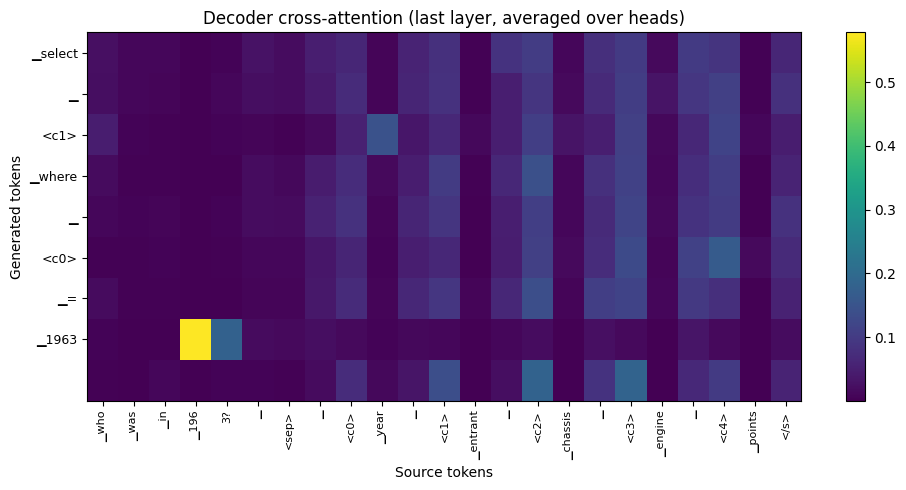

In [115]:
# pick a specific short example instead of just [0]
pairs = read_pairs("dev_pairs.jsonl")
short_examples = sorted(pairs, key=lambda p: len(p["src"]))[:5]
src_example = short_examples[0]["src"]
print(src_example)
generated_text = plot_cross_attention(model, sp, src_example, device)

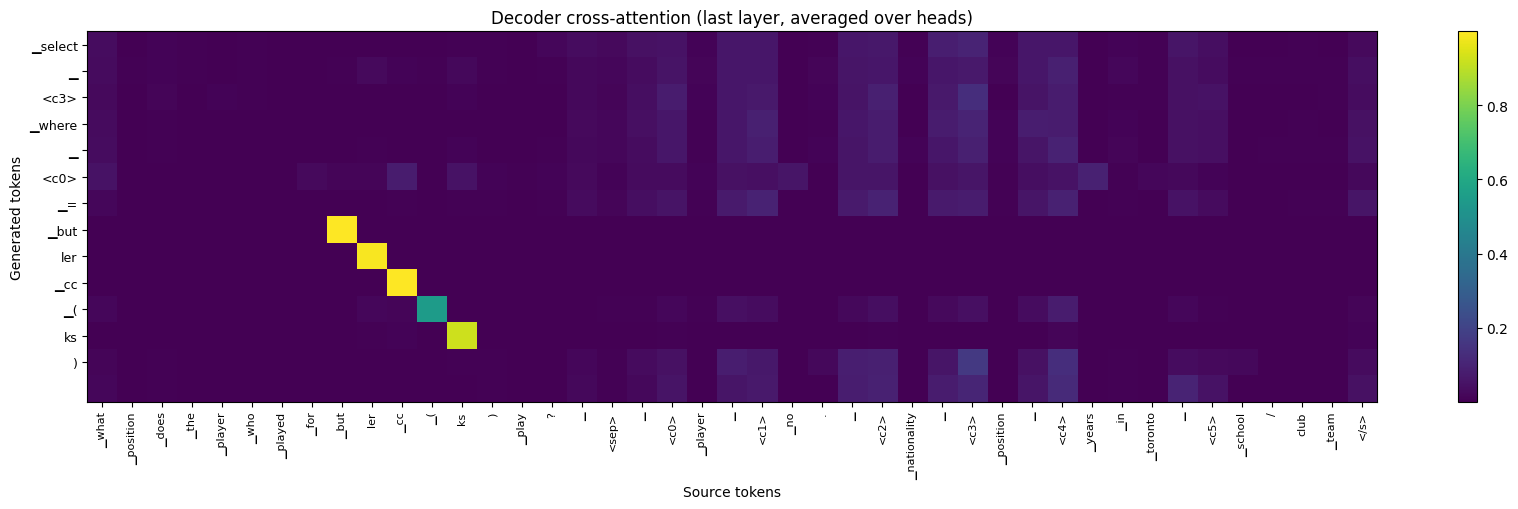

Generated: select <c3> where <c0> = butler cc (ks)


In [116]:
src_example = read_pairs("dev_pairs.jsonl")[0]["src"]
generated_text = plot_cross_attention(model, sp, src_example, device)
print("Generated:", generated_text)

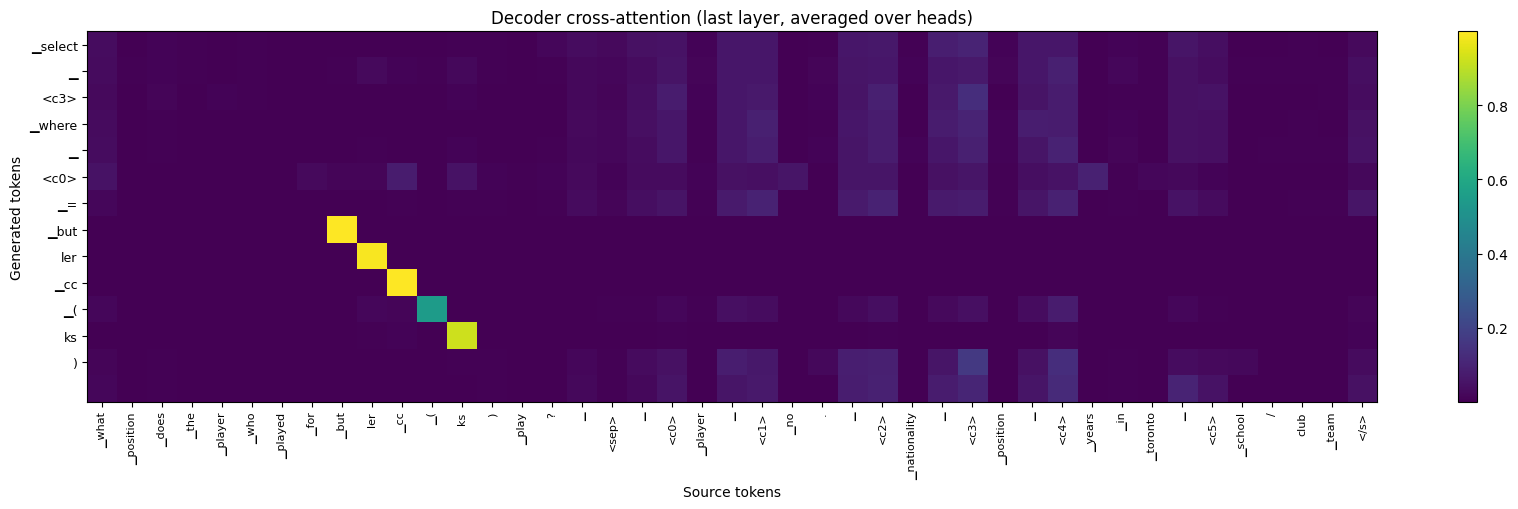

'select <c3> where <c0> = butler cc (ks)'

In [118]:
plot_cross_attention(model, sp, src_example, device)